# Import Dependency

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline
import matplotlib.pyplot as plt
from pathlib import Path
from functools import partial

import itertools

import numpy as np
import autograd.numpy as anp
from autograd import value_and_grad as auto_value_and_grad
import nlopt
import matplotlib.pyplot as plt
from top_opt_framework import problems
from top_opt_framework import topo_api
from top_opt_framework import topo_physics
from scipy.ndimage import zoom
import math

# Beam Settings

In [2]:
N = 40
# 5 7 10 13 15 
# beam_stock_prams = np.array([0, 10, 20, 30, 40], dtype=float)
# beam_stock_numbs = np.array([30, 9, 8, 7, 6], dtype=int)

beam_stock_prams = np.array([0, 10, 16, 22, 28, 34, 40], dtype=float)
beam_stock_numbs = np.array([48, 8,8,8,8,8,8], dtype=int)

img_h = 300
img_w = 300
inventory_type_span_counts = np.random.multinomial(N, [0.25,  0.25])
print(inventory_type_span_counts)

grid_w = 200   # W (number of columns, x-direction)
grid_h = 80   # H (number of rows, y-direction)
sharpness = 2
target_penalty = 10
boundary_penalty = 10
stock_length_penalty = 10
grad_loss_penalty = 1
n_shapes = N

[16 24]


# Basis Function (Sec. 3.3)

In [3]:
import math
import autograd.numpy as anp

# linear hat function B_i centered at l_cur, support (l_prev, l_next)
def hat_func(l, l_prev, l_cur, l_next, has_prev, has_next):
    if has_prev:
        left_val = (l - l_prev) / (l_cur - l_prev)
        left_val = anp.where((l > l_prev) & (l <= l_cur), left_val, 0.0)
    else:
        left_val = anp.where(l <= l_cur, 1.0, 0.0)

    if has_next:
        right_val = (l_next - l) / (l_next - l_cur)
        right_val = anp.where(l > l_cur, right_val, 0.0)
        right_val = anp.where(l > l_next, 0.0, right_val)
    else:
        right_val = 0.0

    return left_val + right_val

def midpoint_hat_func(l, l_i, l_ip1):
    mid = (l_i + l_ip1) / 2.0

    left_val = (l - l_i) / (mid - l_i)
    left_val = anp.where((l > l_i) & (l <= mid), left_val, 0.0)

    right_val = (l_ip1 - l) / (l_ip1 - mid)
    right_val = anp.where((l > mid) & (l < l_ip1), right_val, 0.0)

    return left_val + right_val


# L_stock: softplus barrier on stock inventory violation, Eq. (10)
def soft_stock_func(lens, beam_stock_prams, beam_stock_numbs, eta_s=5.0):
    # lens = anp.asarray(lens)
    M = len(beam_stock_prams)

    bucket_counts = []
    for j in range(M):
        has_prev = j > 0
        has_next = j < M - 1
        l_prev = beam_stock_prams[j - 1] if has_prev else 0.0
        l_cur = beam_stock_prams[j]
        l_next = beam_stock_prams[j + 1] if has_next else 0.0

        s = anp.sum(hat_func(lens, l_prev, l_cur, l_next, has_prev, has_next))
        bucket_counts.append(s)

    total_stock_nums = anp.stack(bucket_counts)
    cost = anp.sum(anp.log1p(anp.exp(eta_s * (total_stock_nums - beam_stock_numbs))))
    return cost


# L_rounding: drives beam lengths toward discrete stock lengths, Eq. (12)
def rounding_func(lens, beam_stock_prams):
    # lens = anp.asarray(lens)
    cost = 0.0
    for i in range(len(beam_stock_prams) - 1):
        b = midpoint_hat_func(lens, beam_stock_prams[i], beam_stock_prams[i + 1])
        cost = cost + anp.sum(b ** 2)
    return cost


# Beam Merging (Sec. 3.6)

In [4]:
"""
beam_postprocess  (length model consistent with _beam_grids_soft / params_to_joints)
====================
Geometry:
    long-axis direction: d = [-sin theta, cos theta]
    length: len = (1-alpha) * H[bt] + alpha * H[bt+1]   <- interpolated between adjacent stock heights
    endpoints: A = center + (len/2) * d,  B = center - (len/2) * d

Key points:
1. Not compacted: the array length always stays N.
2. A merged-away beam is soft-deleted: alpha = 0, beam_type = 0
   (i.e. it degenerates to the shortest stock height H[0]; if H[0] == 0 the length
   is exactly 0). A keep_mask is returned; keep[j] == False means beam j was
   deleted, and downstream code can filter with keep_mask or alpha == 0.
3. The pairwise loop skips deleted beams via keep, so soft-deleted beams no
   longer take part in later merges/splits.

Unified rule (coverage never shrinks): for every pair of parallel, laterally
collinear beams, project onto the shared long axis:
    - overlap, or gap <= merge_gap:
        union_len <= H[-1]  -> merge into one (beam i takes the union, beam j soft-deleted)
        union_len >  H[-1] with overlap -> split at the overlap midpoint, end-to-end
        union_len >  H[-1] but only a small gap -> keep as is
    - gap > merge_gap: disjoint, skip.

Constraint: the shortest producible length is H[0]. A target length < H[0] is
clipped to H[0] (splits keep each segment >= half the original, so this normally
never triggers; if it does it is logged).
"""

import numpy as np


# ─────────────────────── length model (matches _beam_grids_soft) ─────────────

def beam_length(alpha, bt, H):
    """len = (1-alpha)*H[bt] + alpha*H[bt+1]"""
    return (1.0 - alpha) * H[bt] + alpha * H[bt + 1]


def length_to_type_alpha(L, H, eps=1e-12):
    """Inverse: given a target length L, return (bt, alpha) so that
    beam_length(alpha, bt, H) == L.

    L is clipped to the feasible range [H[0], H[-1]].
    Returns (bt, alpha, clipped); clipped=True means L was outside the stock range.
    """
    H = np.asarray(H, dtype=float)
    L_clip = float(np.clip(L, H[0], H[-1]))
    clipped = abs(L_clip - L) > 1e-9
    k = int(np.searchsorted(H, L_clip, side='right') - 1)
    k = min(max(k, 0), len(H) - 2)          # L == H[-1] falls into the last segment
    span = H[k + 1] - H[k]
    a = 0.0 if span <= eps else (L_clip - H[k]) / span
    return k, float(np.clip(a, 0.0, 1.0)), clipped


# ─────────────────────────── beam geometry ───────────────────────────────────

def _long_axis(theta):
    return np.array([-np.sin(theta), np.cos(theta)])


def _get_beam(params, n, i):
    return (params[0*n+i], params[1*n+i],
            params[2*n+i], params[3*n+i])   # cx, cy, theta, alpha


def _endpoints(cx, cy, theta, hl):
    d = _long_axis(theta)
    c = np.array([cx, cy])
    return c + hl*d, c - hl*d, d


def _write_interval(params_out, bt_out, n, i, p_lo, p_hi,
                    origin, d, theta, H, log, tag):
    """Write the axis interval [p_lo, p_hi] back into beam i: solve for (bt, alpha), sync theta."""
    L = p_hi - p_lo
    k, a, clipped = length_to_type_alpha(L, H)
    if clipped:
        log.append(f"[warn] beam {i} target len={L:.2f} clipped to "
                   f"[{H[0]:.1f},{H[-1]:.1f}] ({tag})")
        L = beam_length(a, k, np.asarray(H, float))
    p_mid = (p_lo + p_hi) / 2.0
    params_out[0*n+i] = origin[0] + p_mid * d[0]
    params_out[1*n+i] = origin[1] + p_mid * d[1]
    params_out[2*n+i] = theta
    params_out[3*n+i] = a
    bt_out[i] = k


def _soft_delete(params_out, bt_out, n, j):
    """Soft-delete beam j: alpha=0, beam_type=0 (degenerate to shortest stock H[0]).

    (x, y, theta) are left untouched and the array length is unchanged;
    the caller tracks state via keep_mask.
    """
    params_out[3*n+j] = 0.0
    bt_out[j] = 0


# ─────────────────────────── geometry helpers ────────────────────────────────

def _are_parallel(ti, tj, angle_tol):
    diff = (ti - tj) % np.pi
    return diff < angle_tol or diff > np.pi - angle_tol


def _lateral_dist(P, origin, d):
    proj = float(np.dot(P - origin, d))
    foot = origin + proj * d
    return float(np.linalg.norm(P - foot))


def _proj(P, origin, d):
    return float(np.dot(P - origin, d))


# ─────────────────────────── main ────────────────────────────────────────────

def postprocess_beams(params, beam_types, inventory_heights,
                      angle_tol=np.deg2rad(5),
                      lateral_tol=2.0,
                      merge_gap=3.0,
                      eps=1e-9):
    """
    Parameters
    ----------
    params            : (4*N,) ndarray  [x | y | theta | alpha]
    beam_types        : (N,) int, per-beam type index (indexes into inventory_heights)
    inventory_heights : stock-height table (i.e. inventory_parameters_height)
    angle_tol         : angular tolerance for parallelism (radians)
    lateral_tol       : lateral (perpendicular) distance tolerance for collinearity
    merge_gap         : endpoints within this gap are also eligible for merging

    Returns
    -------
    params_out, beam_types_out, keep_mask, log
        params_out / beam_types_out have the same length as the input (N beams are never dropped).
        keep_mask : (N,) bool; keep[j]=False means beam j was merged away and
                    soft-deleted (alpha=0, beam_type=0).
        Downstream, filter with keep_mask (recommended) or by testing alpha == 0.

    Guarantee: coverage along the long axis never shrinks (closing a small gap
    may extend it by at most merge_gap).
    """
    H = np.asarray(inventory_heights, dtype=float)
    L_MAX, L_MIN = float(H[-1]), float(H[0])

    params_out = np.asarray(params, dtype=float).copy()
    bt_out     = np.asarray(beam_types, dtype=int).copy()
    n = len(params_out) // 4
    keep = np.ones(n, dtype=bool)
    log = []

    for i in range(n):
        for j in range(i+1, n):
            if not keep[i]:
                break
            if not keep[j]:
                continue

            # Re-read each round to use the latest geometry
            cx_i, cy_i, th_i, al_i = _get_beam(params_out, n, i)
            len_i = beam_length(al_i, bt_out[i], H)
            A_i, B_i, d_i = _endpoints(cx_i, cy_i, th_i, len_i / 2.0)
            origin_i = np.array([cx_i, cy_i])

            cx_j, cy_j, th_j, al_j = _get_beam(params_out, n, j)
            len_j = beam_length(al_j, bt_out[j], H)

            # ── 1. Parallel ─────────────────────────────────────────────
            if not _are_parallel(th_i, th_j, angle_tol):
                continue

            # ── 2. Laterally collinear ──────────────────────────────────
            if _lateral_dist(np.array([cx_j, cy_j]), origin_i, d_i) > lateral_tol:
                continue

            # ── 3. Project onto beam i's long axis, normalize so p_C >= p_D ──
            A_j, B_j, _ = _endpoints(cx_j, cy_j, th_j, len_j / 2.0)
            p_A, p_B = len_i / 2.0, -len_i / 2.0
            p_C = _proj(A_j, origin_i, d_i)
            p_D = _proj(B_j, origin_i, d_i)
            if p_C < p_D:
                p_C, p_D = p_D, p_C

            overlap = min(p_A, p_C) - max(p_B, p_D)
            gap     = -overlap
            if overlap <= 0 and gap > merge_gap:
                continue

            union_lo  = min(p_B, p_D)
            union_hi  = max(p_A, p_C)
            union_len = union_hi - union_lo

            # ── Merge: union fits within one stock length ────────────────
            if union_len <= L_MAX + eps:
                _write_interval(params_out, bt_out, n, i,
                                union_lo, union_hi, origin_i, d_i, th_i,
                                H, log, tag=f"merge {i}&{j}")
                keep[j] = False
                _soft_delete(params_out, bt_out, n, j)
                log.append(f"[M] beams {i}&{j} merged: "
                           f"[{union_lo:.1f},{union_hi:.1f}] len={union_len:.1f} "
                           f"-> beam {i} (type {bt_out[i]}, "
                           f"alpha={params_out[3*n+i]:.3f}), "
                           f"beam {j} soft-deleted (alpha=0)")
                continue

            # ── Small gap but union too long -> keep as is ───────────────
            if overlap <= 0:
                log.append(f"[skip] beams {i}&{j} adjacent (gap={gap:.1f}) "
                           f"but union len={union_len:.1f} > H_max={L_MAX:.1f}")
                continue

            # ── Split: interleaved and union too long -> cut at overlap midpoint, end-to-end ──
            snap = (max(p_B, p_D) + min(p_A, p_C)) / 2.0
            if p_A >= p_C:      # i reaches farther on the right -> i takes the right segment
                iv_i, iv_j = (snap, union_hi), (union_lo, snap)
            else:
                iv_i, iv_j = (union_lo, snap), (snap, union_hi)
            _write_interval(params_out, bt_out, n, i, *iv_i,
                            origin_i, d_i, th_i, H, log, tag=f"split {i}")
            _write_interval(params_out, bt_out, n, j, *iv_j,
                            origin_i, d_i, th_i, H, log, tag=f"split {j}")
            log.append(f"[S] beams {i}&{j} split at snap={snap:.2f}: "
                       f"beam {i} [{iv_i[0]:.1f},{iv_i[1]:.1f}] "
                       f"(type {bt_out[i]})  "
                       f"beam {j} [{iv_j[0]:.1f},{iv_j[1]:.1f}] "
                       f"(type {bt_out[j]})")

    return params_out, bt_out, keep, log


# ─────────────────────────── convenience wrapper ─────────────────────────────

def postprocess_and_report(params, beam_types, inventory_heights,
                           angle_tol=np.deg2rad(5),
                           lateral_tol=2.0,
                           merge_gap=3.0):
    """
    Usage:
        params_post, bt_post, keep, log = postprocess_and_report(
            frames[-1], beam_types, inventory_parameters_height,
        )
        # Array length is unchanged; beams with keep[j]=False are marked alpha=0.
        # Filter with keep downstream, e.g. skip them when building joints:
        joint_xy_init, beam_joint_pairs = params_to_joints(params_post, bt_post)
    """
    params_post, bt_post, keep, log = postprocess_beams(
        params, beam_types, inventory_heights,
        angle_tol=angle_tol, lateral_tol=lateral_tol,
        merge_gap=merge_gap,
    )
    n_M = sum(1 for l in log if l.startswith('[M]'))
    n_S = sum(1 for l in log if l.startswith('[S]'))
    print(f"Post-processing done: {len(keep)} beams, {int(keep.sum())} alive "
          f"({int((~keep).sum())} soft-deleted, alpha=0)")
    print(f"  merges: {n_M}   splits (de-overlap): {n_S}")
    for entry in log:
        print(" ", entry)
    return params_post, bt_post, keep, log

def crop_beams_to_left(params, beam_types, inventory_heights,
                       axis_x=0.0, tol=1e-9):
    """Crop all beams to the half-plane x <= axis_x (cut along each beam's long axis).

    Parametrize each beam as point(t) = center + t*d, t in [-len/2, len/2],
    d = [-sin theta, cos theta]. Keep the subinterval with x(t) <= axis_x, re-solve
    (bt, alpha), move the center; if the subinterval is empty (whole beam on the
    right) soft-delete it (alpha=0, bt=0). Returns (params_out, bt_out, log); array
    length unchanged.
    """
    H = np.asarray(inventory_heights, dtype=float)
    p = np.asarray(params, dtype=float).copy()
    bt = np.asarray(beam_types, dtype=int).copy()
    n = len(p) // 4
    log = []
    for i in range(n):
        cx, cy, th, al = p[0*n+i], p[1*n+i], p[2*n+i], p[3*n+i]
        hl = beam_length(al, int(bt[i]), H) / 2.0
        d = np.array([-np.sin(th), np.cos(th)])

        if abs(d[0]) < tol:                       # vertical beam: x is always cx
            if cx > axis_x + tol:
                p[3*n+i] = 0.0; bt[i] = 0
                log.append(f"[del ] beam {i} entirely on the right (vertical, cx={cx:.2f}), soft-deleted")
            continue

        t_axis = (axis_x - cx) / d[0]             # x(t) = cx + t*d_x = axis_x
        if d[0] > 0:
            t_lo, t_hi = -hl, min(hl, t_axis)     # x increases with t -> keep t <= t_axis
        else:
            t_lo, t_hi = max(-hl, t_axis), hl

        if t_hi - t_lo <= tol:                    # whole beam on the right
            p[3*n+i] = 0.0; bt[i] = 0
            log.append(f"[del ] beam {i} entirely on the right, soft-deleted")
            continue

        if t_lo > -hl + tol or t_hi < hl - tol:   # needs cropping
            L = t_hi - t_lo
            tm = (t_lo + t_hi) / 2.0
            k, a, clipped = length_to_type_alpha(L, H)
            p[0*n+i] = cx + tm * d[0]
            p[1*n+i] = cy + tm * d[1]
            p[3*n+i] = a
            bt[i] = k
            log.append(f"[crop] beam {i}: len {2*hl:.2f} -> {L:.2f}"
                       + (" (length clipped)" if clipped else ""))
    return p, bt, log


In [5]:
# ---------- beam params -> joint_xy_init + beam_joint_pairs ----------
def params_to_joints(params_flat, beam_types, tol=1e-6):
    """
    params_flat: (4N,) flat params [x | y | theta | alpha]
    beam_types:  (N,) per-beam type index
    tol:         endpoint merge tolerance; endpoints closer than tol are treated as one joint

    Returns:
        joint_xy_init:    (M, 2) float, de-duplicated joint coordinates
        beam_joint_pairs: (N, 2) int,   (start_index, end_index) per beam
    """
    N = len(params_flat) // 4
    x, y, theta, alpha = np.asarray(params_flat).reshape(4, N)

    # length interpolation, consistent with half_h in _beam_grids_soft
    bt = np.asarray(beam_types, dtype=int)
    Harr = np.array(inventory_parameters_height, dtype=float)
    half_h = ((1 - alpha) * Harr[bt] + alpha * Harr[bt + 1]) / 2.0

    # beam axis = (-sin theta, cos theta)
    dx = -np.sin(theta) * half_h
    dy =  np.cos(theta) * half_h
    p0 = np.stack([x - dx, y - dy], axis=1)          # (N, 2)
    p1 = np.stack([x + dx, y + dy], axis=1)          # (N, 2)
    endpoints = np.concatenate([p0, p1], axis=0)     # (2N, 2), first N are start points

    # merge endpoints within tolerance -> joint table
    joints = []          # list of (2,) arrays
    idx_of = np.empty(2 * N, dtype=int)
    for k, p in enumerate(endpoints):
        for j, q in enumerate(joints):
            if np.hypot(*(p - q)) < tol:
                idx_of[k] = j
                break
        else:
            idx_of[k] = len(joints)
            joints.append(p)

    joint_xy_init = np.array(joints, dtype=float)                        # (M, 2)
    beam_joint_pairs = np.stack([idx_of[:N], idx_of[N:]], axis=1)        # (N, 2)
    return joint_xy_init, beam_joint_pairs


In [6]:
# ---------- save / load joints + pairs to txt ----------
def save_truss_txt(path, joint_xy_init, beam_joint_pairs):
    with open(path, "w") as f:
        f.write("# joints (x y)\n")
        f.write(f"{len(joint_xy_init)}\n")
        for x, y in joint_xy_init:
            f.write(f"{x:.6f} {y:.6f}\n")
        f.write("# beams (i0 i1)\n")
        f.write(f"{len(beam_joint_pairs)}\n")
        for i0, i1 in beam_joint_pairs:
            f.write(f"{i0} {i1}\n")


def load_truss_txt(path):
    with open(path) as f:
        lines = [ln.strip() for ln in f if ln.strip() and not ln.startswith("#")]
    m = int(lines[0])
    joint_xy_init = np.array([ln.split() for ln in lines[1:1 + m]], dtype=float)
    n = int(lines[1 + m])
    beam_joint_pairs = np.array([ln.split() for ln in lines[2 + m:2 + m + n]], dtype=int)
    return joint_xy_init, beam_joint_pairs


# Beam Parameters Initialization (Sec. 3.4)

In [7]:
import numpy as np
import autograd.numpy as anp

# ---------- Constants ----------
inventory_parameters_height = [0, beam_stock_prams[-1]]
BEAM_WIDTH = 1
N_BEAM_TYPES = len(inventory_parameters_height) - 1


def alphas2lengths(alphas, beam_stock_prams):
    """Convert continuous alpha [0,1] per beam to a continuous height in [h_min, h_max]."""
    h1 = beam_stock_prams[0]
    h2 = beam_stock_prams[-1]
    return (1 - alphas) * h1 + alphas * h2


# ---------- Sampling ----------
def random_continuous_params(N, x_range, y_range):
    """Returns flat (4N,) array: [x | y | theta | alpha]."""
    x     = np.random.uniform(x_range[0], x_range[1], N)
    y     = np.random.uniform(y_range[0], y_range[1], N)
    theta = np.random.uniform(0, np.pi, N)
    alpha = np.random.uniform(0, 1, N)
    return np.concatenate([x, y, theta, alpha])

def initialize_params(N, x_range, y_range):
    """Returns flat (4N,) array: [x | y | theta | alpha]."""
    # uniform: all beams parallel, along the middle of the domain, alpha=1
    x = np.linspace(x_range[0] + 5, x_range[1] - 5, N)
    y = np.full(N, (y_range[0] + y_range[1]) / 2)
    theta = np.ones(N) * 0
    alpha = np.full(N, 1)
    return np.concatenate([x, y, theta, alpha])


def random_beam_types(N):
    """Discrete, not optimized."""
    return np.random.randint(0, N_BEAM_TYPES, N)


# ---------- Per-beam soft mask: analytic, evaluated directly on the target grid,
#            differentiable, no resampling ----------
def _beam_grids_soft(params, beam_types, grid_w, grid_h, x_range, y_range, sharpness):
    N = params.shape[0]
    cx, cy, th, al = params[:, 0], params[:, 1], params[:, 2], params[:, 3]
    bt = np.asarray(beam_types, dtype=int)
    Harr = np.array(inventory_parameters_height, dtype=float)
    half_h = ((1 - al) * Harr[bt] + al * Harr[bt + 1]) / 2.0   # (N,) differentiable in alpha
    half_w = BEAM_WIDTH / 2.0

    # world coordinates of the target grid (same grid as oc_x, constant)
    xs = np.linspace(x_range[0], x_range[1], grid_w)
    ys = np.linspace(y_range[0], y_range[1], grid_h)
    XX, YY = np.meshgrid(xs, ys)                                # (H,W)

    # grid point -> each beam's local frame (inverse rotation)
    dx = XX[None, :, :] - cx[:, None, None]                     # (N,H,W)
    dy = YY[None, :, :] - cy[:, None, None]
    c = anp.cos(th)[:, None, None]
    s = anp.sin(th)[:, None, None]
    lx =  c * dx + s * dy
    ly = -s * dx + c * dy

    # soft rectangle: product of two sigmoids (differentiable substitute for a boolean test)
    sx = 1.0 / (1.0 + anp.exp(-sharpness * (half_w                 - anp.abs(lx))))
    sy = 1.0 / (1.0 + anp.exp(-sharpness * (half_h[:, None, None]  - anp.abs(ly))))

    # gate so that half_h == 0 forces the beam's contribution to zero.
    # gate_y = 1 - exp(-k * half_h); with k = 2*sharpness it matches the sigmoid scale.
    gate_y = 1.0 - anp.exp(-2.0 * sharpness * half_h[:, None, None])
    return sx * sy * gate_y


# ---------- Density map ----------
def params_to_density_map(params_batch, beam_types, grid_w, grid_h,
                          x_range, y_range, sdf_x_range=None, sdf_y_range=None,
                          sharpness=2.0):
    """
    params_batch: flat (4N,) anp array (optimization variables)
    beam_types:   (N,) np array (fixed discrete choice)
    Returns (grid_h, grid_w), density in [0.001, 1], differentiable.
    """
    N = params_batch.shape[0] // 4
    params = params_batch.reshape(4, N).T                       # (N,4), keeps gradient

    soft = _beam_grids_soft(params, beam_types, grid_w, grid_h,
                            x_range, y_range, sharpness)
    union = 1.0 - anp.prod(1.0 - soft, axis=0)                  # soft union in (0,1)
    density = union * (1.0 - 0.001) + 0.001                     # map to [0.001, 1]
    return density


# ---------- Overlap map ----------
def params_to_overlap_map(params_batch, beam_types, grid_w, grid_h,
                          x_range, y_range, sdf_x_range=None, sdf_y_range=None,
                          sharpness=2.0):
    """Returns (grid_h, grid_w): per-pixel sum of the beam soft masks, measures overlap. Differentiable."""
    N = params_batch.shape[0] // 4
    params = params_batch.reshape(4, N).T
    soft = _beam_grids_soft(params, beam_types, grid_w, grid_h,
                            x_range, y_range, sharpness)
    return anp.sum(soft, axis=0)


In [8]:
# ══════════════════════════════════════════════════════════════════════════
#  Left-right mirror symmetry
#  Optimization variable x_half: (4*n_half,) = [x | y | theta | alpha], describing
#  only the left-half beams. The full structure = left half + its mirror about x=0:
#      cx -> -cx,  cy -> cy,  theta -> -theta,  alpha -> alpha
#  (long axis d = [-sin theta, cos theta]; mirroring requires (dx,dy) -> (-dx,dy),
#   i.e. theta' = -theta.)
#  mirror_params is written entirely in anp and is differentiable: the
#  compliance/overlap gradients of the right half flow back to the left-half params.
# ══════════════════════════════════════════════════════════════════════════
import numpy as np
import autograd.numpy as anp

assert n_shapes % 2 == 0, "n_shapes must be even to split left/right"
n_half = n_shapes // 2          # number of actually-optimized beams (left half)


def mirror_params(x_half):
    """(4*n_half,) -> (4*n_shapes,). First n_half beams are the left half, next n_half are the mirror."""
    n = x_half.shape[0] // 4
    cx = x_half[0 * n:1 * n]
    cy = x_half[1 * n:2 * n]
    th = x_half[2 * n:3 * n]
    al = x_half[3 * n:4 * n]
    return anp.concatenate([cx, -cx,     # x block: left + mirror
                            cy,  cy,     # y block
                            th, -th,     # theta block
                            al,  al])    # alpha block


def initialize_params_half(n_half, x_range, y_range):
    """Lay out initial beams only on the left half (x<0)."""
    x = np.linspace(x_range[0] + 5, -5.0, n_half)
    y = np.full(n_half, (y_range[0] + y_range[1]) / 2 + 20)
    theta = np.zeros(n_half)
    alpha = np.random.uniform(0.25, 1, n_half)
    return np.concatenate([x, y, theta, alpha])


def full_to_half_params(params_full, atol=1e-9):
    """Extract the cx<0 half from a left-right symmetric full params (4*2m,) as the
    initial guess for mirrored optimization. Warns if the left-side beam count is not
    exactly half (e.g. some beam sits exactly on cx=0)."""
    m2 = params_full.shape[0] // 4
    cx = params_full[0 * m2:1 * m2]
    idx = np.where(cx < -atol)[0]
    if len(idx) != m2 // 2:
        print(f"[warn] left-side beam count {len(idx)} != {m2 // 2}; "
              f"{np.sum(np.abs(cx) <= atol)} beam(s) sit on the center line cx=0")
    parts = [params_full[k * m2:(k + 1) * m2][idx] for k in range(4)]
    return np.concatenate(parts)

# Notes:
# 1) Beams near the center line overlap their own mirror; overlap_loss pushes them
#    apart. Collinear overlapping pairs are merged into one during postprocessing.
# 2) The inventory constraint counts the FULL structure: each left-side beam's
#    length is consumed twice (see half_lengths_mirrored).


In [9]:
# ---------- Driver ----------
sdf_x_range = (-25, 25)
sdf_y_range = (-25, 25)
x_range = (-100, 100)
y_range = (-40, 40)

# ---- Symmetric setup: the optimization variable is only the left-half n_half beams ----
params_batch    = initialize_params_half(n_half, x_range, y_range)     # (4*n_half,)
beam_types_half = random_beam_types(n_half)                            # (n_half,)
beam_types      = np.concatenate([beam_types_half, beam_types_half])   # full 2*n_half, mirror beams share the type

density_map = params_to_density_map(
    mirror_params(params_batch), beam_types,
    grid_w=grid_w, grid_h=grid_h,
    x_range=x_range, y_range=y_range,
    sdf_x_range=sdf_x_range, sdf_y_range=sdf_y_range, sharpness=sharpness
)
overlap_map = params_to_overlap_map(
    mirror_params(params_batch), beam_types,
    grid_w=grid_w, grid_h=grid_h,
    x_range=x_range, y_range=y_range,
    sdf_x_range=sdf_x_range, sdf_y_range=sdf_y_range, sharpness=sharpness
)


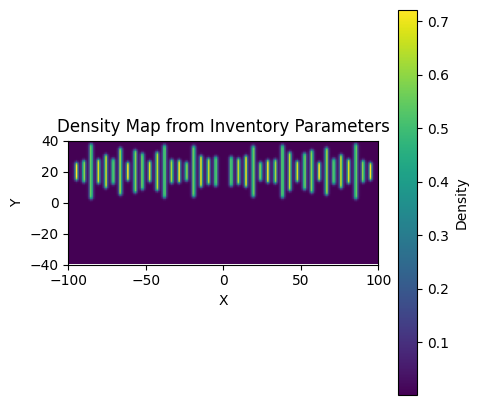

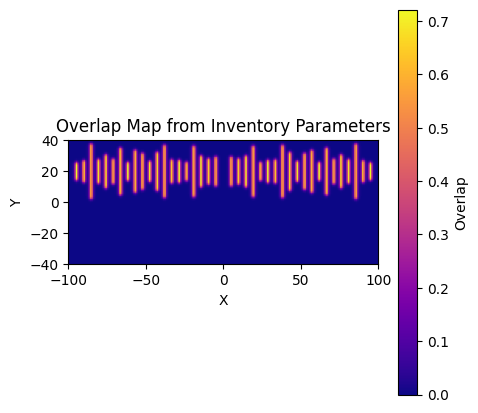

In [10]:
# visualize the density map
plt.figure(figsize=(5, 5))
plt.imshow(density_map, extent=(x_range[0], x_range[1], y_range[0], y_range[1]), origin='lower', cmap='viridis')
plt.title('Density Map from Inventory Parameters')
plt.xlabel('X')
plt.ylabel('Y')
plt.colorbar(label='Density')
plt.show()

# visualize the overlap map
plt.figure(figsize=(5, 5))
plt.imshow(overlap_map, extent=(x_range[0], x_range[1], y_range[0], y_range[1]), origin='lower', cmap='plasma')
plt.title('Overlap Map from Inventory Parameters')
plt.xlabel('X')
plt.ylabel('Y')
plt.colorbar(label='Overlap')
plt.show()

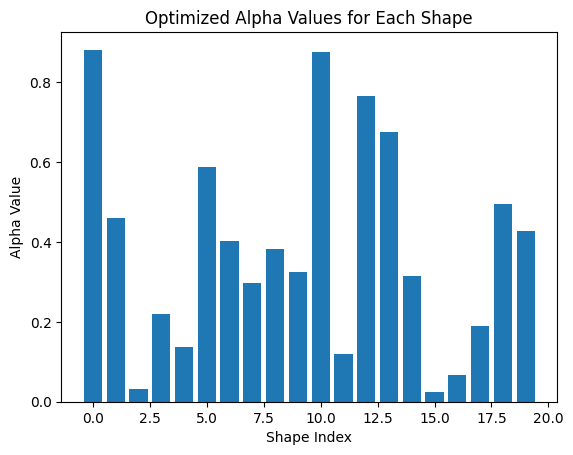

In [11]:
# show alphas
params_batch[3*n_half:4*n_half] = np.random.uniform(0, 1, n_half)
alphas = params_batch.reshape(4, n_half)[3]
plt.bar(range(n_half), alphas)
plt.xlabel("Shape Index")
plt.ylabel("Alpha Value")
plt.title("Optimized Alpha Values for Each Shape")
plt.show()


# Boundary Condition Settings

2 fixed nodes


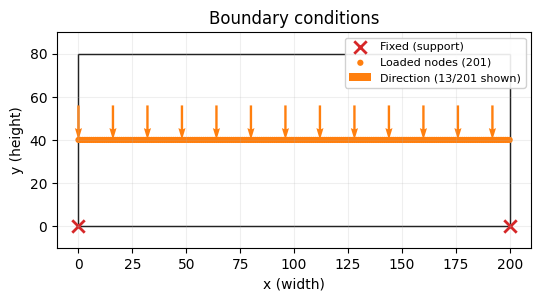

In [12]:
import numpy as np
import matplotlib.pyplot as plt

def plot_boundary_conditions(problem, ax=None, density=None,
                             pad=None, load_stride=None, fix_stride=1):
    """Visualize a Problem's supports (normals) and loads (forces).

    pad:         extra space around the domain so out-of-frame arrows stay visible.
                 Default: 10% of max(W,H).
    load_stride: subsample for the load DIRECTION arrows only (every k-th node).
                 Default: auto-pick so ~12 arrows are shown.
                 All loaded nodes are still marked with an orange dot regardless.
    fix_stride:  subsample fixed-node crosses (default 1 = show all).
    """
    normals = np.asarray(problem.normals)
    forces  = np.asarray(problem.forces)
    Wp1, Hp1, _ = normals.shape
    W, H = Wp1 - 1, Hp1 - 1

    if pad is None:
        pad = 0.10 * max(W, H)

    if ax is None:
        _, ax = plt.subplots(figsize=(7, 7 * H / max(W, 1)))

    if density is not None:
        ax.imshow(np.asarray(density).T, origin='lower', cmap='gray_r',
                  extent=(0, W, 0, H), vmin=0, vmax=1, alpha=0.6)
    else:
        ax.add_patch(plt.Rectangle((0, 0), W, H, fill=False, ec='black', lw=1))

    ii, jj = np.meshgrid(np.arange(Wp1), np.arange(Hp1), indexing='ij')

    # --- Fixed nodes: red cross ---------------------------------------
    fixed_any = (normals[..., 0] > 0) | (normals[..., 1] > 0)
    fix_i, fix_j = ii[fixed_any], jj[fixed_any]
    if fix_stride > 1 and len(fix_i):
        fix_i = fix_i[::fix_stride]; fix_j = fix_j[::fix_stride]
    print(len(fix_i), "fixed nodes")
    ax.scatter(fix_i, fix_j, marker='x', s=80, c='tab:red', linewidths=2,
               label='Fixed (support)')

    # --- Loads --------------------------------------------------------
    fxv = forces[..., 0]; fyv = forces[..., 1]
    has_load = (fxv != 0) | (fyv != 0)
    li_all, lj_all = ii[has_load], jj[has_load]

    # (a) Mark EVERY loaded node with an orange dot
    if len(li_all):
        ax.scatter(li_all, lj_all, marker='o', s=20,
                   c='tab:orange', edgecolors='none',
                   label=f'Loaded nodes ({len(li_all)})')

    # (b) Sparse direction arrows on top
    lux_all = fxv[has_load]; luy_all = fyv[has_load]
    n_loads = len(li_all)
    if n_loads:
        if load_stride is None:
            load_stride = max(1, n_loads // 12)     # ~12 arrows by default
        sel = slice(None, None, load_stride)
        li, lj = li_all[sel], lj_all[sel]
        lux, luy = lux_all[sel], luy_all[sel]
        mag = np.sqrt(lux**2 + luy**2) + 1e-12
        ux, uy = lux / mag, luy / mag
        arrow_len = 0.08 * max(W, H)
        # Place arrow so the tip sits ON the node.
        x0 = li - ux * arrow_len
        y0 = lj - uy * arrow_len
        ax.quiver(x0, y0, ux * arrow_len, uy * arrow_len,
                  angles='xy', scale_units='xy', scale=1.0,
                  color='tab:orange', width=0.005,
                  label=f'Direction ({len(li)}/{n_loads} shown)')

    ax.set_xlim(-pad, W + pad)
    ax.set_ylim(-pad, H + pad)
    ax.set_aspect('equal')
    ax.set_xlabel('x (width)'); ax.set_ylabel('y (height)')
    ax.set_title('Boundary conditions')
    ax.legend(loc='upper right', fontsize=8, framealpha=0.9)
    ax.grid(alpha=0.2)
    return ax


problem = problems.bridge_half(height=grid_h, width=grid_w)
args = topo_api.specified_task(problem)
args["youngs_modulus"] = 1.0
args["volfrac"]=0.1
args["filter_width"]=2
args["g"]=0
env = topo_api.Environment(args)

nely = grid_h
nelx = grid_w

# x is the left-half params (4*n_half,): mirror to the full structure before rasterizing.
density_func = lambda x : params_to_density_map(
    mirror_params(x), beam_types=beam_types,
    grid_w=grid_w, grid_h=grid_h,
    x_range=x_range, y_range=y_range,
    sdf_x_range=sdf_x_range, sdf_y_range=sdf_y_range, sharpness=sharpness
)
overlap_func = lambda x: params_to_overlap_map(
    mirror_params(x), beam_types=beam_types,
    grid_w=grid_w, grid_h=grid_h,
    x_range=x_range, y_range=y_range,
    sdf_x_range=sdf_x_range, sdf_y_range=sdf_y_range, sharpness=sharpness
)
compliance_fn = lambda x: env.objective(density_func(x), volume_constraint=False)

# Usage: plot_boundary_conditions(problem, pad=5, load_stride=8)   # very sparse
plot_boundary_conditions(problem, pad=10)                  # auto stride
plt.show()


# Density Method (SIMP)

In [13]:
density_frames = []
oc_iterations = 50
# (grid_h x grid_w) ones-like array  (rows=H, cols=W)
oc_x = np.ones((grid_h, grid_w)) * 0.13
for it in range(oc_iterations):
    c, x_next = topo_physics.optimality_criteria_step(oc_x, env.ke, env.args)
    # x_next[62:120, :] = 0.001
    # x_next[50:, 50:] = 0.001
    density_frames.append(x_next.copy())
    if np.isnan(c):
        print(f"NaN encountered at iteration {it}, stopping.")
        break
    oc_x = x_next

# oc_x = (oc_x >= 0.4).astype(float)

In [14]:
oc_x[:,:] = 0.01
oc_x[62:120, :] = 1.01
# oc_x[50:, 50:] = 1.01
# oc_x[:,125:] = 1.01

In [15]:
cx = grid_h / 2.0
cols = np.arange(grid_w)
h_frac = 1 - cols / (grid_w - 1)                      
hw = (0.06 + 0.44 * h_frac**3) * grid_h
rows = np.arange(grid_h)
mask = np.abs(rows[:, None] - cx) <= hw[None, :]
oc_x = np.where(mask, 0.0, 1.0)

In [16]:
env.objective(oc_x)

52707476.09462391

In [17]:
np.mean(oc_x)

0.6600625

# Visualize the Gradient Flow

compliance = 1749895176.7104
sens shape  = (80, 200)  min/max = -199063781475.6703 692.8142833950243


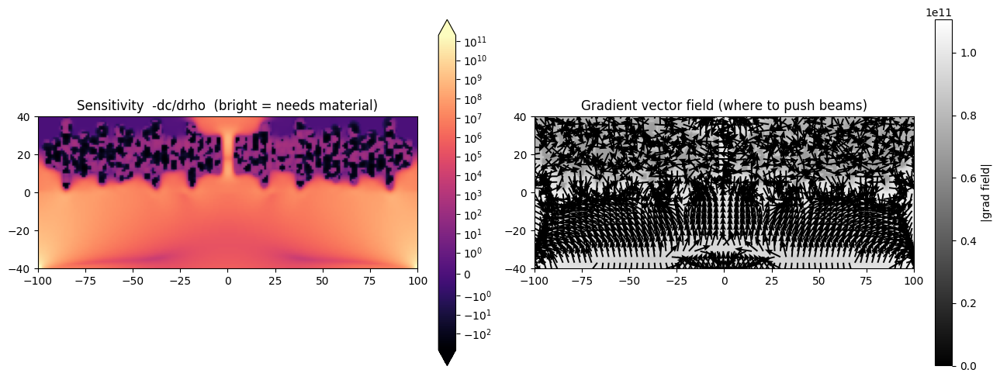

In [18]:
import autograd.numpy as anp
from autograd import value_and_grad as auto_value_and_grad
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from matplotlib.colors import SymLogNorm

# 1) density field -- here the solid field with beams laid out
density0 = density_map

def sensitivity_loss(density):
    compliance_grad = auto_value_and_grad(env.objective)(density)[1]
    sensitivity_norm = (compliance_grad - compliance_grad.min()) / (compliance_grad.max() - compliance_grad.min() + 1e-8)
    dark_weight = 1.0 - sensitivity_norm
    return anp.sum(density * dark_weight)

def overlap_loss(x):
    return anp.sum(anp.log1p(anp.exp(5 * (x - 1))))

# 2) gradient of compliance w.r.t. each pixel density (sensitivity field)
compliance, sens = auto_value_and_grad(
    lambda d:
      env.objective(d, volume_constraint=False)
)(density0)

print("compliance =", float(compliance))
print("sens shape  =", sens.shape, " min/max =", sens.min(), sens.max())

# 3) sensitivity field
field = -sens                      # larger = more material should be added here

# no material should be added inside a beam: push existing-material cells to the min
# (do this in numpy, not anp)
field = np.asarray(field, dtype=float)
# field[density0 > 0.5] = field.min()

gy, gx = np.gradient(field)        # gy: along rows (y), gx: along cols (x)

# downsample so the arrows do not clump
step = max(1, min(grid_h, grid_w) // 22)
ys, xs = np.mgrid[0:grid_h:step, 0:grid_w:step]
U = gx[::step, ::step]
V = gy[::step, ::step]

# normalize to unit vectors: equal-length arrows, magnitude shown by color
mag = np.hypot(U, V)
Un = U / (mag + 1e-8)
Vn = V / (mag + 1e-8)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# left: sensitivity scalar field -- SymLogNorm handles cross-magnitude + negative values
im = ax[0].imshow(
    field, origin='lower', extent=(*x_range, *y_range), cmap='magma',
    norm=SymLogNorm(linthresh=1, vmin=field.min(), vmax=field.max())
)
ax[0].set_title("Sensitivity  -dc/drho  (bright = needs material)")
plt.colorbar(im, ax=ax[0], fraction=0.046, extend='both')

# right: vector field
ax[1].imshow(field, origin='lower', extent=(*x_range, *y_range),
             cmap='gray', alpha=0.4,
             norm=SymLogNorm(linthresh=1, vmin=field.min(), vmax=field.max()))
xw = anp.interp(xs, [0, grid_w - 1], x_range)
yw = anp.interp(ys, [0, grid_h - 1], y_range)

q = ax[1].quiver(xw, yw, Un, Vn, mag,
                 cmap='gray', angles='xy',
                 scale_units='width', scale=22,
                 width=0.004,
                 headwidth=4, headlength=5, headaxislength=4.5)
plt.colorbar(q, ax=ax[1], fraction=0.046, label='|grad field|')
ax[1].set_title("Gradient vector field (where to push beams)")
ax[1].set_xlim(x_range); ax[1].set_ylim(y_range)
plt.tight_layout(); plt.show()


In [19]:
print("nan:", np.isnan(field).sum(), " inf:", np.isinf(field).sum())
print("range:", np.nanmin(field), np.nanmax(field))

nan: 0  inf: 0
range: -692.8142833950243 199063781475.6703


# Objective Function Settings (Sec. 3.3)

In [20]:
sharpness = 2
weight_compliance = 5
weight_overlap = 10
weight_length = 100
weight_stock = 1000
weight_rounding = 10


In [21]:
# add a constraint function to make x similar to oc_x

def boundary_loss(params_batch, beam_types, x_range, y_range):
    N = params_batch.shape[0] // 4
    params = params_batch.reshape(4, N).T  # (N, 4)

    xs     = params[:, 0]
    ys     = params[:, 1]
    thetas = params[:, 2]
    alphas = params[:, 3]

    # Beam half-extents in local frame
    beam_types = np.asarray(beam_types, dtype=int)
    heights_arr = np.array(inventory_parameters_height)
    h1 = heights_arr[beam_types]
    h2 = heights_arr[beam_types + 1]
    heights = (1 - alphas) * h1 + alphas * h2  # (N,) anp
    hw = BEAM_WIDTH / 2.0
    hh = heights / 2.0                          # (N,) anp

    # 4 corners in local frame, shape (N, 4, 2)
    # Order: (-hw,-hh), (+hw,-hh), (+hw,+hh), (-hw,+hh)
    sign_x = np.array([-1.0, 1.0, 1.0, -1.0])   # (4,)
    sign_y = np.array([-1.0, -1.0, 1.0, 1.0])   # (4,)
    local_x = sign_x[np.newaxis, :] * hw                    # (1, 4)
    local_y = sign_y[np.newaxis, :] * hh[:, np.newaxis]     # (N, 4)

    # Rotate + translate to world frame
    c = anp.cos(thetas)[:, np.newaxis]  # (N, 1)
    s = anp.sin(thetas)[:, np.newaxis]
    world_x = c * local_x - s * local_y + xs[:, np.newaxis]  # (N, 4)
    world_y = s * local_x + c * local_y + ys[:, np.newaxis]

    # Penalize amount outside the box (squared hinge)
    x_min, x_max = x_range
    y_min, y_max = y_range
    over = (anp.maximum(0.0, x_min - world_x) ** 2
          + anp.maximum(0.0, world_x - x_max) ** 2
          + anp.maximum(0.0, y_min - world_y) ** 2
          + anp.maximum(0.0, world_y - y_max) ** 2)

    return anp.sum(over)

def overlap_loss(x):
    return anp.sum(anp.log1p(anp.exp(5 * (x - 0.75))))

boundary_fn = lambda x: boundary_loss(mirror_params(x), beam_types, x_range, y_range)
overlap_fn = lambda x: (overlap_loss(overlap_func(x)))
constraint_fn = lambda x: (density_func(x)*oc_x).sum()

def gradloss_fn(x):
    density_field = density_func(x)
    compliance_grad = auto_value_and_grad(env.objective)(density_field)[1]
    _LOG10 = anp.log(10.0)
    compliance_grad_log = anp.sign(compliance_grad) * anp.log(anp.abs(compliance_grad) + 1e-5) / _LOG10
    min_grad_log = anp.min(compliance_grad_log)
    compliance_grad_log = compliance_grad_log - min_grad_log
    return anp.sum(compliance_grad_log*density_field)

match_target_fn = lambda x: anp.sum(anp.abs(density_func(x) - oc_x))

def compliance_sens_loss(x):
    density_field = density_func(x)
    compliance_grad = auto_value_and_grad(env.objective)(density_field)[1]
    compliance_grad = anp.log10(- compliance_grad + 1e-5)
    return anp.sum(compliance_grad * density_field)

def sensitivity_weighted_coverage_loss(x):
    density = density_func(x)
    compliance_grad = auto_value_and_grad(env.objective)(density)[1]
    sensitivity_norm = (compliance_grad - compliance_grad.min()) / (compliance_grad.max() - compliance_grad.min() + 1e-8)
    dark_weight = 1.0 - sensitivity_norm
    return anp.sum(density * dark_weight)

def alpha_sum_loss(x):
    alphas = x.reshape(4, n_half)[3]
    return 2 * anp.sum(alphas)   # x2: mirroring doubles the total material


def half_lengths_mirrored(x):
    """Left-half alpha -> length, then duplicated: mirror beams consume stock too."""
    lens = alphas2lengths(x.reshape(4, n_half)[3], beam_stock_prams)
    return anp.concatenate([lens, lens])

def volume_loss(x):
    density = density_func(x)
    return (((anp.mean(density) - 0.066)*100)**2)**5

def avoid_region_loss(x, avoid_mask):
    density_field = density_func(x)
    overlap_with_mask = density_field * avoid_mask
    return anp.sum(overlap_with_mask)

avoid_fn = lambda x: avoid_region_loss(x, avoid_mask=oc_x)

objective_fn = lambda x: (
    compliance_fn(x)*weight_compliance
    + overlap_fn(x)*weight_overlap
    + alpha_sum_loss(x)*weight_length
    + soft_stock_func(half_lengths_mirrored(x), beam_stock_prams, beam_stock_numbs)* stock_length_penalty*weight_stock
    + rounding_func(half_lengths_mirrored(x), beam_stock_prams)*weight_rounding
)


In [22]:
loss, g = auto_value_and_grad(objective_fn)(params_batch)


/Users/cavers/miniconda3/envs/gp/lib/python3.10/site-packages/autograd/numpy/numpy_vjps.py:125: RuntimeWarning: overflow encountered in square
  lambda ans, x, y: unbroadcast_f(y, lambda g: -g * x / y**2),


In [23]:
def topology_optmization(x, optimizer, iterations, ls_max_backtracks, ls_shrink, ls_tol, alpha_frozen_threshold):
    # N is counted from x (= n_half); no dependence on a global.
    N = x.shape[0] // 4

    lower = torch.tensor([-100.]*N + [-80.]*N + [-float(np.inf)]*N + [0.]*N, dtype=torch.float64)
    upper = torch.tensor([ 0.]*N   + [ 80.]*N + [ float(np.inf)]*N + [1.]*N, dtype=torch.float64)

    alpha_idx_start = 3 * N
    alpha_frozen = np.zeros(N, dtype=bool)

    losses, frames = [], []

    x0_np = x.detach().cpu().numpy().copy()
    frames.append(x0_np)
    losses.append(float(objective_fn(x0_np)))

    pbar = tqdm(total=iterations, desc="Optimizing", unit="step")
    for t in range(iterations):
        grad_mask_np = np.ones(4 * N, dtype=np.float64)
        grad_mask_np[alpha_idx_start:][alpha_frozen] = 0.0
        grad_mask = torch.tensor(grad_mask_np, dtype=torch.float64)

        x_np = x.detach().cpu().numpy()
        loss, g = auto_value_and_grad(objective_fn)(x_np)
        loss_prev = float(loss)

        x_prev = x.detach().clone()

        optimizer.zero_grad()
        g_t = torch.tensor(np.asarray(g, dtype=float), dtype=torch.float64) * grad_mask
        x.grad = g_t
        optimizer.step()
        with torch.no_grad():
            if alpha_frozen.any():
                xd = x.detach().cpu().numpy()
                xd[alpha_idx_start:][alpha_frozen] = 0.0
                x.copy_(torch.tensor(xd, dtype=torch.float64))
            x.clamp_(lower, upper)

        # ---- Backtracking line search ----
        scale = 1.0
        accepted_loss = loss_prev
        for _ in range(ls_max_backtracks):
            with torch.no_grad():
                new_loss = float(objective_fn(x.detach().cpu().numpy()))
            if np.isfinite(new_loss) and new_loss <= loss_prev * (1.0 + ls_tol):
                accepted_loss = new_loss
                break
            scale *= ls_shrink
            with torch.no_grad():
                x_interp = x_prev + scale * (x - x_prev) / (scale / ls_shrink)
                if alpha_frozen.any():
                    xi = x_interp.detach().cpu().numpy()
                    xi[alpha_idx_start:][alpha_frozen] = 0.0
                    x_interp = torch.tensor(xi, dtype=torch.float64)
                x.copy_(x_interp.clamp_(lower, upper))
        else:
            with torch.no_grad():
                x.copy_(x_prev)
            accepted_loss = loss_prev

        # ---- After the step is accepted: round any alpha < threshold to 0 and freeze ----
        with torch.no_grad():
            xd = x.detach().cpu().numpy()
            alpha_now = xd[alpha_idx_start:alpha_idx_start + N]
            newly = (alpha_now < alpha_frozen_threshold) & (~alpha_frozen)
            if newly.any():
                xd[alpha_idx_start:alpha_idx_start + N][newly] = 0.0
                x.copy_(torch.tensor(xd, dtype=torch.float64))
                alpha_frozen |= newly

                # Clear Adam's running moments on the newly frozen positions.
                state = optimizer.state.get(x, None)
                if state is not None and 'exp_avg' in state:
                    idxs = np.where(newly)[0] + alpha_idx_start
                    idx_t = torch.tensor(idxs, dtype=torch.long)
                    state['exp_avg'].view(-1)[idx_t]    = 0.0
                    state['exp_avg_sq'].view(-1)[idx_t] = 0.0

        losses.append(accepted_loss)
        frames.append(x.detach().cpu().numpy().copy())
        pbar.update(1)
        loss_compliance = compliance_fn(x.detach().cpu().numpy())
        pbar.set_postfix(
            loss=f"{accepted_loss:.4f}",
            compliance=f"{loss_compliance:.4f}",
            thick=f"{thickness:.3f}",
            scale=f"{scale:.2f}",
            dead=f"{int(alpha_frozen.sum())}/{N}",
        )
    pbar.close()
    return x.detach().cpu().numpy(), losses, frames


In [24]:
import torch, numpy as np
from tqdm.notebook import tqdm

iterations = 200
ls_max_backtracks = 16
ls_shrink = 0.5
ls_tol = 1e-3
alpha_frozen_threshold = 0.1
sharpness = 2
thickness_start, thickness_end = sharpness, sharpness
thickness = sharpness

# Multi-stage schedule. A numeric value is an Adam learning rate for one
# topology_optmization run; -1 triggers a postprocess (merge overlaps) whose
# result is fed back as the starting point of the next stage.
lr_schedule = [1, 0.5, 0.1, -1, 0.1, -1, 0.1]

# start from the left-half init
x = torch.tensor(np.array(params_batch), dtype=torch.float64, requires_grad=True)

all_frames, all_losses = [], []
frames = [x.detach().cpu().numpy().copy()]     # defensive init in case the schedule starts with -1

for cur_lr in lr_schedule:
    if cur_lr == -1:
        # ---- postprocess on the half params (old 4-tuple API), then feed back ----
        # ── 1. postprocess directly on the half params (no mirror) ───────────────────
        params_post_half, bt_post_half, keep, log = postprocess_and_report(
            frames[-1], beam_types_half, inventory_parameters_height,
            angle_tol=np.deg2rad(5),
            lateral_tol=5.0,
            merge_gap=3.0,
        )

        # # ── 2. crop: remove the part reaching across the symmetry axis (x=0) ─────────
        params_post_half, bt_post_half, crop_log = crop_beams_to_left(
            params_post_half, bt_post_half, inventory_parameters_height, axis_x=0.0)
        for entry in crop_log:
            print(" ", entry)

        params_post = np.asarray(params_post_half, dtype=float)
        beam_types_half = np.asarray(bt_post_half, dtype=int)

        x      = torch.tensor(np.array(params_post_half), dtype=torch.float64, requires_grad=True)
        frames = [params_post.copy()]
        all_frames.append(params_post.copy())
        all_losses.append(float(objective_fn(params_post)))
        continue

    optimizer = torch.optim.Adam([x], lr=cur_lr)
    x, losses, frames = topology_optmization(
        x, optimizer, iterations, ls_max_backtracks, ls_shrink, ls_tol, alpha_frozen_threshold)
    all_frames.extend(frames)
    all_losses.extend(losses)
    x = torch.tensor(np.array(x), dtype=torch.float64, requires_grad=True)

x_opt = x.detach().cpu().numpy()
x_opt_full = mirror_params(x_opt)   # mirror to the full structure for postprocessing / visualization

# expose the accumulated history under the names the downstream cells use
frames = all_frames
losses = all_losses


Optimizing:   0%|          | 0/50 [00:00<?, ?step/s]

/Users/cavers/miniconda3/envs/gp/lib/python3.10/site-packages/autograd/numpy/numpy_vjps.py:125: RuntimeWarning: overflow encountered in square
  lambda ans, x, y: unbroadcast_f(y, lambda g: -g * x / y**2),


Optimizing:   0%|          | 0/50 [00:00<?, ?step/s]

Optimizing:   0%|          | 0/50 [00:00<?, ?step/s]

Post-processing done: 20 beams, 19 alive (1 soft-deleted, alpha=0)
  merges: 1   splits (de-overlap): 0
  [M] beams 5&9 merged: [-19.2,14.3] len=33.5 -> beam 5 (type 0, alpha=0.838), beam 9 soft-deleted (alpha=0)
  [del ] beam 2 entirely on the right, soft-deleted
  [del ] beam 4 entirely on the right, soft-deleted
  [del ] beam 9 entirely on the right, soft-deleted
  [del ] beam 10 entirely on the right, soft-deleted
  [del ] beam 12 entirely on the right, soft-deleted
  [del ] beam 15 entirely on the right, soft-deleted
  [del ] beam 17 entirely on the right, soft-deleted
  [crop] beam 18: len 23.11 -> 12.76
  [crop] beam 19: len 29.62 -> 14.81


Optimizing:   0%|          | 0/50 [00:00<?, ?step/s]

Post-processing done: 20 beams, 19 alive (1 soft-deleted, alpha=0)
  merges: 1   splits (de-overlap): 1
  [M] beams 5&7 merged: [-13.8,20.6] len=34.4 -> beam 5 (type 0, alpha=0.860), beam 7 soft-deleted (alpha=0)
  [S] beams 5&11 split at snap=-14.30: beam 5 [-14.3,17.2] (type 0)  beam 11 [-44.8,-14.3] (type 0)
  [del ] beam 2 entirely on the right, soft-deleted
  [del ] beam 4 entirely on the right, soft-deleted
  [del ] beam 7 entirely on the right, soft-deleted
  [del ] beam 8 entirely on the right, soft-deleted
  [del ] beam 9 entirely on the right, soft-deleted
  [del ] beam 10 entirely on the right, soft-deleted
  [del ] beam 12 entirely on the right, soft-deleted
  [del ] beam 15 entirely on the right, soft-deleted
  [del ] beam 17 entirely on the right, soft-deleted
  [crop] beam 18: len 31.18 -> 25.49
  [crop] beam 19: len 15.57 -> 15.08


Optimizing:   0%|          | 0/50 [00:00<?, ?step/s]

# Final Results

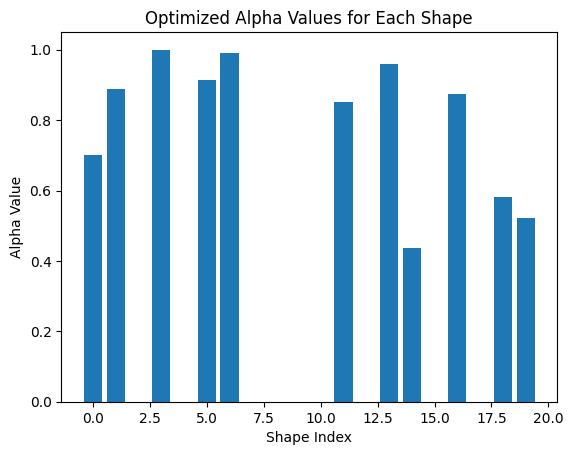

In [25]:
# show alphas
alphas = frames[-1].reshape(4, n_half)[3]
plt.bar(range(n_half), alphas)
plt.xlabel("Shape Index")
plt.ylabel("Alpha Value")
plt.title("Optimized Alpha Values for Each Shape")
plt.show()


In [26]:
final_lengs = alphas2lengths(alphas, beam_stock_prams)
print("Final lengths:", final_lengs)

nearest_idx = np.argmin(np.abs(final_lengs[:, None] - beam_stock_prams[None, :]), axis=1)
# reassign each length to the nearest stock length
nearest_idx_alphas = (beam_stock_prams[nearest_idx] - beam_stock_prams[0]) / (beam_stock_prams[-1] - beam_stock_prams[0])
x_opt_reassigned = x_opt.copy()
x_opt_reassigned[3*n_half:4*n_half] = nearest_idx_alphas

final_beam_lengths_distribution = np.bincount(nearest_idx, minlength=len(beam_stock_prams))
print("Final distribution:", final_beam_lengths_distribution)
print("Target distribution:", beam_stock_numbs)
print("Diff:", final_beam_lengths_distribution - beam_stock_numbs)


Final lengths: [28.05771306 35.53983205  0.         40.          0.         36.60410084
 39.66434832  0.          0.          0.          0.         34.07752288
  0.         38.39298109 17.49135459  0.         35.00981091  0.
 23.28621252 20.85016726]
Final distribution: [9 0 1 2 1 4 3]
Target distribution: [48  8  8  8  8  8  8]
Diff: [-39  -8  -7  -6  -7  -4  -5]


Final Loss: 511.9636175115163


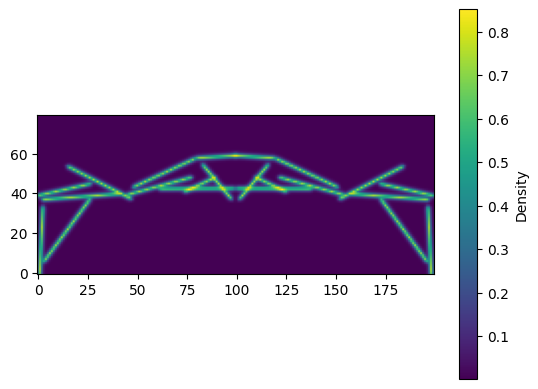

In [27]:
frame = frames[-1].copy()
density_field = params_to_density_map(
    mirror_params(frame), beam_types=beam_types,
    grid_w=grid_w, grid_h=grid_h,
    x_range=x_range, y_range=y_range,
    sdf_x_range=sdf_x_range, sdf_y_range=sdf_y_range, sharpness=sharpness
)

fig, ax = plt.subplots()
plt.colorbar(ax.imshow(density_field, origin='lower'), ax=ax, label='Density')
ax.imshow(density_field, origin='lower')
temp_density_field = density_field.copy()
temp_density_field[temp_density_field > 0.4] = 1
print("Final Loss:", env.objective(temp_density_field, volume_constraint=False))


In [28]:
from matplotlib.animation import FuncAnimation
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from IPython.display import HTML

def animate_frames(frames, shape=None, interval=100, save_path=None):
    if shape is None:
        shape = (grid_h, grid_w)

    cmap_bw = mcolors.LinearSegmentedColormap.from_list('density', ['white', '#111111'])

    fig, ax = plt.subplots(figsize=(8, 6), facecolor='white')
    fig.subplots_adjust(right=0.85)

    im = ax.imshow(frames[0].reshape(shape), cmap=cmap_bw, origin='lower', vmin=0, vmax=1)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

    cbar_ax = fig.add_axes([0.88, 0.12, 0.02, 0.76])
    cb = fig.colorbar(im, cax=cbar_ax)
    cb.set_label('Density', fontsize=11)
    cb.set_ticks([0, 0.5, 1.0])
    cb.set_ticklabels(['0', '0.5', '1'])

    def update(frame):
        im.set_array(frame.reshape(shape))
        return [im]

    anim = FuncAnimation(fig, update, frames=frames, interval=interval, blit=True)

    if save_path is not None:
        if save_path.endswith(".mp4"):
            anim.save(save_path, writer='ffmpeg', fps=1000//interval)
        elif save_path.endswith(".gif"):
            anim.save(save_path, writer='pillow', fps=1000//interval)
        else:
            raise ValueError("Unsupported format. Use .mp4 or .gif")

    plt.close(fig)
    return HTML(anim.to_jshtml())


import numpy as np
from scipy.ndimage import uniform_filter1d

raw = np.array([mirror_params(frame) for frame in all_frames])          # (T, 4*n_shapes) 完整参数
# smooth = uniform_filter1d(raw, size=5, axis=0, mode='nearest')      # 可选：跨帧平滑
anime_frames = [
    params_to_density_map(f, beam_types=beam_types,
                          grid_w=grid_w, grid_h=grid_h,
                          x_range=x_range, y_range=y_range,
                          sdf_x_range=sdf_x_range, sdf_y_range=sdf_y_range,
                          sharpness=sharpness)
    for f in raw                                            # 或 raw[::10] 不平滑
]
animate_frames(anime_frames, save_path="./teaser_result.gif")

In [29]:
# ---------- export joints + edges per frame to a single txt ----------
# depends on alphas2lengths / beam_stock_prams already defined in the notebook

def params_to_joints_v2(params_flat, tol=1e-6):
    N = len(params_flat) // 4
    x, y, theta, alpha = np.asarray(params_flat).reshape(4, N)

    half_h = alphas2lengths(alpha, beam_stock_prams) / 2.0

    dx = -np.sin(theta) * half_h
    dy =  np.cos(theta) * half_h
    p0 = np.stack([x - dx, y - dy], axis=1)
    p1 = np.stack([x + dx, y + dy], axis=1)
    endpoints = np.concatenate([p0, p1], axis=0)     # (2N, 2)

    joints, idx_of = [], np.empty(2 * N, dtype=int)
    for k, p in enumerate(endpoints):
        for j, q in enumerate(joints):
            if np.hypot(*(p - q)) < tol:
                idx_of[k] = j
                break
        else:
            idx_of[k] = len(joints)
            joints.append(p)

    joint_xy = np.array(joints, dtype=float)
    pairs = np.stack([idx_of[:N], idx_of[N:]], axis=1)
    return joint_xy, pairs


def save_frames_truss_txt(path, frames, stride=1, tol=1e-6, drop_zero_length=False):
    frames_sel = frames[::stride]
    with open(path, "w") as f:
        f.write("# n_frames\n")
        f.write(f"{len(frames_sel)}\n")
        for k, frame in enumerate(frames_sel):
            joint_xy, pairs = params_to_joints_v2(frame, tol=tol)

            if drop_zero_length:
                keep = pairs[:, 0] != pairs[:, 1]          # zero-length beams collapse both ends to one joint
                pairs = pairs[keep]
                used = np.unique(pairs)                     # drop isolated joints and reindex
                remap = -np.ones(len(joint_xy), dtype=int)
                remap[used] = np.arange(len(used))
                joint_xy = joint_xy[used]
                pairs = remap[pairs]

            f.write(f"# frame {k}\n")
            f.write("# joints (x y)\n")
            f.write(f"{len(joint_xy)}\n")
            for x, y in joint_xy:
                f.write(f"{x:.6f} {y:.6f}\n")
            f.write("# beams (i0 i1)\n")
            f.write(f"{len(pairs)}\n")
            for i0, i1 in pairs:
                f.write(f"{i0} {i1}\n")


def load_frames_truss_txt(path):
    """Read back -> list of (joint_xy (M,2), pairs (N,2))"""
    with open(path) as f:
        lines = [ln.strip() for ln in f if ln.strip() and not ln.startswith("#")]
    n_frames = int(lines[0])
    out, pos = [], 1
    for _ in range(n_frames):
        m = int(lines[pos]); pos += 1
        joint_xy = np.array([ln.split() for ln in lines[pos:pos + m]], dtype=float); pos += m
        n = int(lines[pos]); pos += 1
        pairs = np.array([ln.split() for ln in lines[pos:pos + n]], dtype=int); pos += n
        out.append((joint_xy, pairs))
    return out


save_frames_truss_txt("./results/teaser.txt", all_frames, stride=1)